# WICOS: envelope features (Amin et al., 2019)
This notebook implements the envelope features of

> M. G. Amin, Z. Zeng and T. Shan, "Hand Gesture Recognition based on Radar Micro-Doppler Signature Envelopes," *IEEE RadarConf*, 2019 (`docs/Hand_Gesture_Recognition_based_on_Radar_Micro-Doppler_Signature_Envelopes.pdf`).

**Idea of the paper.** A hand gesture is described by the *outline* of its micro-Doppler signature: the **positive frequency envelope** $e_U(n)$ (the highest velocity towards the radar at time $n$) and the **negative frequency envelope** $e_L(n)$ (the highest velocity away from the radar). According to the paper, these two curves together capture the maximum positive and negative Doppler, the length of the gesture, its bandwidth, and the balance between motion towards and away from the radar. The feature vector is the two curves themselves, $e = [e_U, e_L]$.

**The algorithm (Sec. II-B):**
1. Compute the **effective bandwidth** of the gesture spectrum; it defines the maximum positive and negative Doppler.
2. Split the spectrogram into a positive and a negative Doppler half and compute their energy per time bin, $E_U(n)$ and $E_L(n)$ (eq. 2).
3. Scale the energies to thresholds $T_U(n) = \sigma_U E_U(n)$ and $T_L(n) = \sigma_L E_L(n)$ with $\sigma < 1$ (eq. 3). The paper suggests choosing $\sigma$ so that the ratio of energy to threshold is the one found at the maximum Doppler.
4. The envelope at time $n$ is the outermost Doppler bin where the spectrogram is still at or above the threshold.

The functions are in `src/features.py`; `features.extract_features` gives the features stored in the dataset (`src/build_dataset.py`). This notebook first runs every step on **one spectrogram**, then checks the envelopes on **one training sample per gesture**. Classification is not part of this notebook: the models are trained and compared in the model notebooks. Everything that is checked or chosen here uses the training samples only.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# The feature functions and the data loading live in src/
sys.path.insert(0, str(Path("../src").resolve()))
import features as F
from build_dataset import GESTURES, load_data, split

# Figures for the report
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(exist_ok=True)

# All spectrograms (dB) with their metadata, and the fixed train/test split
spectrograms, metadata = load_data()
idx_train, idx_test, cv_fold = split(metadata)
labels, persons = metadata.label.to_numpy(), metadata.person.to_numpy()
y_train = labels[idx_train]
doppler = F.doppler_axis()  # Doppler bin of every row, relative to zero Doppler
EMPIRICAL = ["length", "peak_ratio", "doppler_bandwidth"]  # the paper's T, R and B_w

## Example: one spectrogram, step by step
**Gesture power and gesture span.** The paper works on the spectrogram $S(n, k)$ of one gesture. We use the **gesture power** $P(d, t)$, i.e. the linear power above the sample's own noise floor (same noise removal as the images, `src/preprocessing.py`), so that pure noise has power 0. Unlike the images, the Doppler axis is **not cropped**: all 800 Doppler bins are kept, because nothing is rescaled here. The paper cuts every recording into 1-second windows that each contain one complete gesture. Our recordings have different lengths with silence before and after the gesture, so we keep the **gesture span**: from the first to the last time bin with at least 5% of the power of the strongest time bin.

**Step 1: effective bandwidth.** Within the span, the gesture power of each half is summed over time, giving the spectrum of that half. Counting outward from zero Doppler, the **effective bandwidth** ends where 99.9% of the half's energy is reached (`EFFECTIVE_BANDWIDTH`); that Doppler bin is the maximum positive Doppler $f_p$ and maximum negative Doppler $f_n$ of the gesture. The paper does not say how the effective bandwidth is computed; a fixed energy share is a common choice. The share is taken on linear power, where a lobe 20 dB below the peak carries only about 1% of the energy: a share of 99% would cut off the outer lobes of the gesture, while 99.9% includes them. Isolated noise cells far from zero Doppler carry almost no energy, so they stay outside.

**Steps 2 and 3: energy per half and threshold.** $E_U(n)$ and $E_L(n)$ are the energies of the positive and negative half in every time bin (eq. 2; the paper squares $S$ there, our $P$ is already a power): the sum of the gesture power over that half of one spectrogram column. The threshold is a fixed fraction of it, $T_U(n) = \sigma_U E_U(n)$ and $T_L(n) = \sigma_L E_L(n)$ (eq. 3). As in the paper, $\sigma$ is chosen per sample and per half from the maximum Doppler of step 1: $\sigma = P(f_p, n_p) / E(n_p)$, with $n_p$ the time bin in which $P(f_p, \cdot)$ is largest (`paper_sigma`). In that time bin the threshold therefore lies exactly at the maximum Doppler, and in every other time bin it scales with that time bin's energy.

**Step 4: the envelope.** In every time bin, the envelope is the outermost Doppler bin whose power is still at or above the threshold (`envelopes`). The gesture span, effective bandwidth and envelopes are shown in the figure of step 5 (left).

### Step 5: the feature vector
The paper concatenates the two envelopes, $e = [e_U, e_L]$. Its samples are all 1-second windows with one gesture each, so the envelopes are used at full time resolution, without resampling, and the time bins without gesture are simply 0. Our gesture spans differ in length (51-376 time bins), so each envelope is placed in a **fixed window** of `WINDOW` = 358 time bins, starting at the gesture start and **zero-padded** after the gesture end. 358 is the length into which 99% of the training gesture spans fit; the 7 longer training clips (and 1 test clip) are cut. Nothing is resampled or averaged, so the gesture length stays in the envelope (where the zeros begin), as in the paper. This gives 2 x 358 = 716 features.

The paper's three **empirical features** (Sec. IV-A, its baseline) are computed as well: the length $T = t_e - t_s$, the ratio of the peak frequencies $R = |f_p / f_n|$ and the bandwidth $B_w = |f_p| + |f_n|$.

Below, left: the gesture power of the whole recording, with the gesture span between the vertical dashed lines, the effective bandwidth between the horizontal dashed lines, and the envelopes $e_U$ (white) and $e_L$ (black); time bin 0 is the gesture start. Right: the resulting feature vector, $e_U$ in features 0-357 and $e_L$ in features 358-715.

In [ ]:
# Example sample: the second wave in the training set
i_ex = idx_train[y_train == 0][1]
x_ex = spectrograms[i_ex]

# Gesture power: linear power above the sample's noise floor (pure noise -> 0)
P_full = F.gesture_power(x_ex)
# Gesture span: first to last time bin with >= 5% of the power of the strongest time bin
active = np.flatnonzero(F.active_bins(P_full))
P_ex = F.gesture_span(P_full)
print(f"Sample {i_ex}: {GESTURES[labels[i_ex]]}, Person {persons[i_ex]}; "
      f"{x_ex.shape[1]} time bins, gesture span {active[0]}-{active[-1]} ({P_ex.shape[1]} time bins)")

# Step 1: split the span into the positive and negative Doppler half; in each half the maximum
# Doppler is where 99.9% of the half's energy is reached, counted outward from zero Doppler.
# Step 3's sigma of each half follows from it (printed here; envelopes computes it again).
f_max = {}
for name, sign, (P_half, speed) in zip(("positive", "negative"), (1, -1), F.halves(P_ex, doppler)):
    f_max[name] = sign * F.max_doppler(P_half, speed)
    print(f"{name:8s} half: maximum Doppler {f_max[name]:+d} bins, sigma {F.paper_sigma(P_half, speed):.4f}")

# Steps 2-4: per time bin, energy of each half E(n), threshold sigma * E(n) with the half's own
# sigma, and the envelope as the outermost Doppler bin at or above the threshold
upper, lower = F.envelopes(P_ex, doppler)

# Step 5: each envelope in a fixed window of WINDOW time bins (zero-padded after the gesture),
# concatenated into e = [e_U, e_L]
vector = np.concatenate([F.fixed_window(upper), F.fixed_window(lower)])

# The paper's empirical features T, R and B_w, as stored in the dataset
empirical = {k: v for k, v in F.extract_features(x_ex).items() if k in EMPIRICAL}
print(f"Feature vector: {vector.shape[0]} values; empirical features: {empirical}")

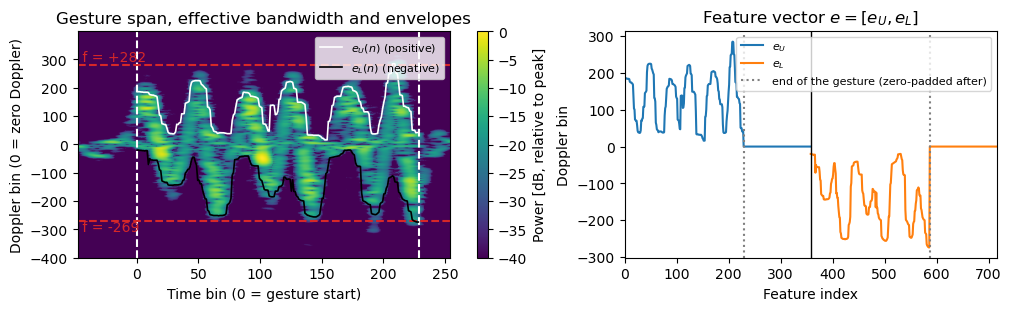

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)

# Left: gesture power of the whole recording in dB relative to its peak (floor at -40 dB),
# shifted so that time bin 0 is the gesture start
ax = axes[0]
im = ax.imshow(10 * np.log10(np.maximum(P_full / P_full.max(), 1e-4)), aspect="auto", origin="lower",
               cmap="viridis", vmin=-40, vmax=0,
               extent=[-active[0], P_full.shape[1] - active[0], doppler[0], doppler[-1]])
# Gesture span: vertical dashed lines at its start and end
for t in (0, P_ex.shape[1]):
    ax.axvline(t, color="white", linestyle="--")
# Effective bandwidth (step 1): horizontal dashed lines at the maximum Doppler of each half
for f in f_max.values():
    ax.axhline(f, color="C3", linestyle="--")
    ax.text(ax.get_xlim()[0], f, f" f = {f:+d}", color="C3", va="bottom" if f > 0 else "top")
# Envelopes (steps 2-4), drawn at the centres of the span's time bins
t = np.arange(len(upper)) + 0.5
ax.plot(t, upper, color="white", linewidth=1.2, label="$e_U(n)$ (positive)")
ax.plot(t, lower, color="black", linewidth=1.2, label="$e_L(n)$ (negative)")
# ax.set_ylim(-300, 300)
ax.set_title("Gesture span, effective bandwidth and envelopes")
ax.set_xlabel("Time bin (0 = gesture start)")
ax.set_ylabel("Doppler bin (0 = zero Doppler)")
ax.legend(fontsize=8, loc="upper right")
fig.colorbar(im, ax=ax, label="Power [dB, relative to peak]")

# Right: the feature vector (step 5), e_U in the first WINDOW features and e_L in the second
ax = axes[1]
i_feat = np.arange(len(vector))
ax.plot(i_feat[:F.WINDOW], vector[:F.WINDOW], color="C0", label="$e_U$")
ax.plot(i_feat[F.WINDOW:], vector[F.WINDOW:], color="C1", label="$e_L$")
ax.axvline(F.WINDOW, color="black", linewidth=1)            # boundary between e_U and e_L
for start in (0, F.WINDOW):                                  # gesture end in each half; zeros after it
    ax.axvline(start + P_ex.shape[1], color="gray", linestyle=":")
ax.plot([], [], color="gray", linestyle=":", label="end of the gesture (zero-padded after)")
ax.set_xlim(0, len(vector))
ax.set_title("Feature vector $e = [e_U, e_L]$")
ax.set_xlabel("Feature index")
ax.set_ylabel("Doppler bin")
ax.legend(fontsize=8)
fig.savefig(FIG_DIR / "amin_envelope_steps.pdf", bbox_inches="tight")
plt.show()

**The example.** The maximum Doppler of this wave is +282 / -269 bins, and the thresholds use $\sigma_U$ = 0.0021 and $\sigma_L$ = 0.0010. The envelopes follow the swings of the wave: at the peak of each swing they reach the outer lobes (up to about +280 and -270, close to the maximum Doppler), and between two swings, when the hand turns, they fall back towards zero Doppler. In the feature vector (right) the gesture ends after 229 time bins; the rest of each window is zero.

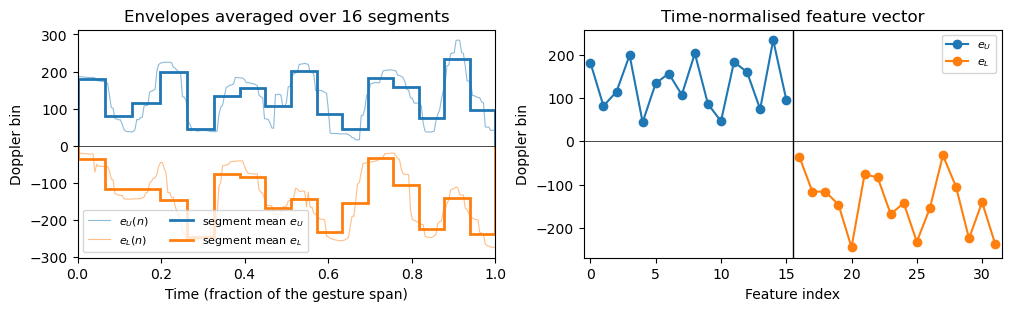

In [11]:
# Time-normalised feature vector of the example: each envelope averaged over NORM_POINTS equal
# segments of the gesture span, concatenated into [e_U, e_L] (the upper_norm/lower_norm features)
norm_upper, norm_lower = F.time_normalised(upper), F.time_normalised(lower)
vector_norm = np.concatenate([norm_upper, norm_lower])

fig, axes = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)

# Left: the envelopes over the gesture span (time as a fraction of the span), with the segment means
ax = axes[0]
t_frac = (np.arange(len(upper)) + 0.5) / len(upper)
edges = np.concatenate([[0], np.cumsum([len(s) for s in np.array_split(upper, F.NORM_POINTS)])]) / len(upper)
ax.plot(t_frac, upper, color="C0", linewidth=0.8, alpha=0.5, label="$e_U(n)$")
ax.plot(t_frac, lower, color="C1", linewidth=0.8, alpha=0.5, label="$e_L(n)$")
ax.stairs(norm_upper, edges, color="C0", linewidth=2, label="segment mean $e_U$")
ax.stairs(norm_lower, edges, color="C1", linewidth=2, label="segment mean $e_L$")
ax.axhline(0, color="black", linewidth=0.5)
ax.set_xlim(0, 1)
ax.set_title(f"Envelopes averaged over {F.NORM_POINTS} segments")
ax.set_xlabel("Time (fraction of the gesture span)")
ax.set_ylabel("Doppler bin")
ax.legend(fontsize=8, ncol=2)

# Right: the time-normalised feature vector, e_U in the first NORM_POINTS features and e_L in the second
ax = axes[1]
i_feat = np.arange(len(vector_norm))
ax.plot(i_feat[:F.NORM_POINTS], vector_norm[:F.NORM_POINTS], "o-", color="C0", label="$e_U$")
ax.plot(i_feat[F.NORM_POINTS:], vector_norm[F.NORM_POINTS:], "o-", color="C1", label="$e_L$")
ax.axvline(F.NORM_POINTS - 0.5, color="black", linewidth=1)  # boundary between e_U and e_L
ax.axhline(0, color="black", linewidth=0.5)
ax.set_xlim(-0.5, len(vector_norm) - 0.5)
ax.set_title("Time-normalised feature vector")
ax.set_xlabel("Feature index")
ax.set_ylabel("Doppler bin")
ax.legend(fontsize=8)
fig.savefig(FIG_DIR / "amin_envelope_normalised.pdf", bbox_inches="tight")
plt.show()

## Check: envelopes on one training sample per gesture
One random training sample of each gesture: the raw spectrogram (dB) with the detected envelopes $e_U$ (white) and $e_L$ (black), drawn over the gesture span at the original time bins.

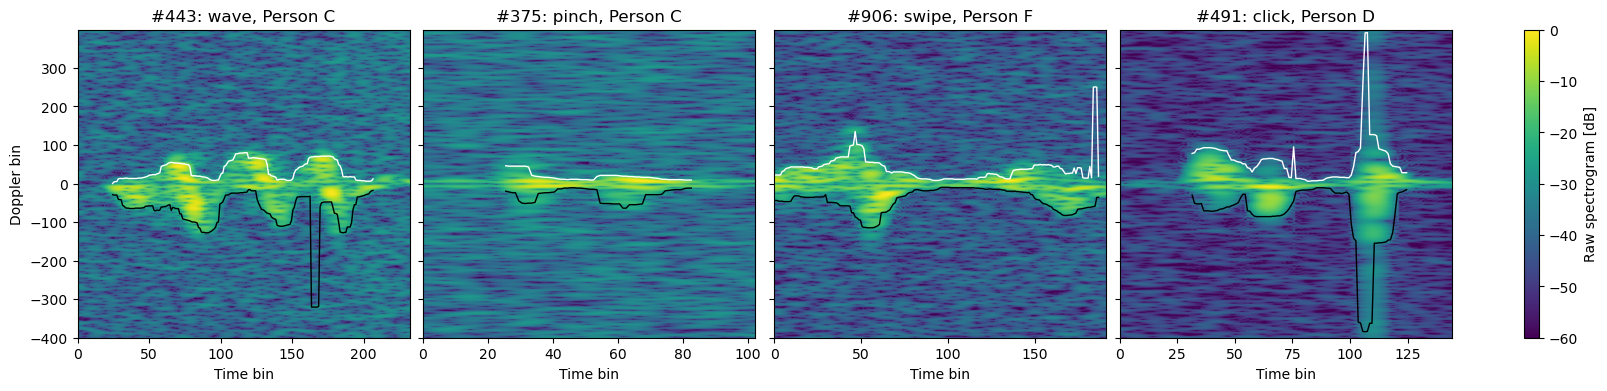

In [10]:
# One random training sample per gesture (fixed seed, so the same samples every run)
rng = np.random.default_rng(0)
sample_idx = [rng.choice(idx_train[y_train == k]) for k in range(len(GESTURES))]

fig, axes = plt.subplots(1, len(sample_idx), figsize=(16, 3.8), sharey=True, constrained_layout=True)
for ax, i in zip(axes, sample_idx):
    # Same steps as in the example: gesture power, gesture span, envelopes
    x = spectrograms[i]
    P_full = F.gesture_power(x)
    start = np.flatnonzero(F.active_bins(P_full))[0]       # first time bin of the gesture span
    up, lo = F.envelopes(F.gesture_span(P_full), doppler)
    t = start + np.arange(len(up)) + 0.5                   # centres of the span's time bins in the recording
    # Raw spectrogram with the envelopes on top, at the original time bins
    im = ax.imshow(x, aspect="auto", origin="lower", cmap="viridis", vmin=-60, vmax=0,
                   extent=[0, x.shape[1], doppler[0] - 0.5, doppler[-1] + 0.5])
    ax.plot(t, up, color="white", linewidth=1)
    ax.plot(t, lo, color="black", linewidth=1)
    # ax.set_ylim(-300, 300)
    ax.set_title(f"#{i}: {GESTURES[labels[i]]}, Person {persons[i]}")
    ax.set_xlabel("Time bin")
axes[0].set_ylabel("Doppler bin")
fig.colorbar(im, ax=axes, label="Raw spectrogram [dB]")
fig.savefig(FIG_DIR / "amin_envelopes_examples.pdf", bbox_inches="tight")
plt.show()

**Observations.**
- The envelopes separate the gestures by their extent: the pinch stays within about ±60 Doppler bins, the swipe mostly within about +50 / -110, the wave swings between about +80 and -125, and the click has one wide excursion.
- **Jumps in weak time bins.** Where a time bin holds little gesture energy, the threshold $\sigma E(n)$ is so low that single noise cells far from zero Doppler pass it. The wave (#443) jumps to about -320 for a few time bins around time bin 165, between two swings; the swipe (#906) jumps to about +250 in its last time bins.
- **The click's broadband stripe.** Around time bin 108 the click (#491) has a short stripe that covers almost the whole Doppler axis, so both envelopes jump to the edge of the axis. This is the click itself (the broadband stripe seen in the data exploration), not noise, but it gives clicks much larger envelope values than the other gestures.

## Conclusion
- The envelope method of Amin et al. (2019) is implemented as described in the paper (Sec. II-B): effective bandwidth, energy per half, threshold $\sigma E(n)$ with $\sigma$ chosen per sample and per half at the maximum Doppler, outermost cell above the threshold, and $e = [e_U, e_L]$. The adaptations are the gesture span and a fixed, zero-padded window of 358 time bins instead of the paper's 1-second window (DopNet recordings have different lengths), and an effective bandwidth of 99.9% of the energy (the paper does not define it).
- In clean time bins the envelopes follow the outline of the gesture, including the outer lobes. The weak point is the threshold per time bin: in time bins with little gesture energy (pauses, the start and end of the gesture) it is so low that single noise cells far from zero Doppler pass it, and the envelope jumps.
- **Possible improvements.** One threshold for the whole spectrogram (e.g. 25 dB below its strongest cell) instead of one per time bin would avoid the jumps in weak time bins. Remaining noise specks and stationary noise lines (Person B) could be removed from the thresholded spectrogram by removing small connected regions and thin horizontal structures.
- `features.extract_features` (the features in the dataset) gives the window envelopes, the empirical features $T$, $R$, $B_w$, the time-normalised envelopes, the envelope statistics and the recording length (`duration`). Which of these each model uses is chosen in the model notebooks.